<a href="https://colab.research.google.com/github/jorgecaraveobalderas-beep/Class-Files/blob/main/%C3%81rboles_de_Regresi%C3%B3n_274702_Sesion_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Árboles de Regresión
### Maestría en Inteligencia Artificial y Analítica de Datos
**Módulo:** Analítica Predictiva · Sesión 12

**Dataset:** California Housing

**Nombre:** Jorge Alberto Caraveo Balderas

**Matricula** 274702

---

## Contenido del Notebook

| Bloque | Tema |
|--------|------|
| 1 | Carga y exploración de datos |
| 2 | Preparación de datos |
| 3 | Modelo base |
| 4 | Análisis Bias–Variance |
| 5 | Poda del árbol |
| 6 | Interpretación de resultados |

## Bloque 1 · Carga y exploración de datos

- 1.-Cargar librerias y el dataset en un DataFrame
- 2.-Identificar la variable objetivo (`MedHouseVal`)
- 3.-Analizar la estructura del dataset (`info`, `describe`)
- 4.-Visualizar la distribución de la variable objetivo

In [29]:
# 1.- Cargar librerias y el dataset en un DataFrame
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

housing = fetch_california_housing(as_frame=True)
df = housing.frame
print(df.head())

# 2.-Identificar la variable objetivo (MedHouseVal)
print("\nVariable objetivo del dataset:", housing.target_names)
print(df['MedHouseVal'].describe())


   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Variable objetivo del dataset: ['MedHouseVal']
count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3

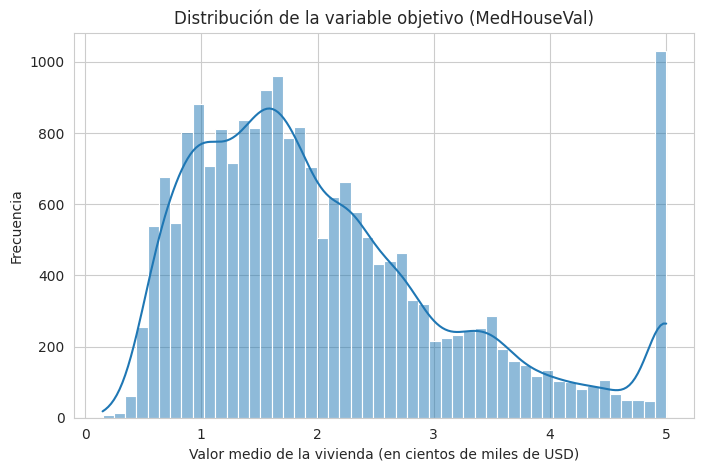

In [30]:
# 3.-Analizar la estructura del dataset (info, describe)
print()
print(df.info())
print(df.describe())

# 4.-Visualizar la distribución de la variable objetivo
sns.set_style("whitegrid")
plt.figure(figsize=(8, 5))
sns.histplot(df['MedHouseVal'], bins=50, kde=True)
plt.title("Distribución de la variable objetivo (MedHouseVal)")
plt.xlabel("Valor medio de la vivienda (en cientos de miles de USD)")
plt.ylabel("Frecuencia")
plt.show()

### Conclusion - Bloque 1 Carga y exploracion de datos

* **Estructura e integridad de los datos:** El conjunto de datos cuenta con 20,640 registros y 9 columnas numericas de tipo float64. Esta compuesto por 8 variables predictoras y 1 variable objetivo `MedHouseVal`. No existen valores nulos ni registros vacios en ninguna columna, por lo que no se requiere imputacion

* **Comportamiento de la variable objetivo (`MedHouseVal`):** El valor medio de las viviendas presenta un promedio de 2.06 y una mediana de 1.79, con una desviacion estandar de 1.15

* **Distribucion y truncamiento en el histograma:** La variable `MedHouseVal`presenta un sesgo positivo hacia la derecha, concentrando la mayor parte de las observaciones entre 1.0 y 2.5. Se observa un pico notable en el valor maximo de 5 (eje x), lo que indica un tope en los datos del censo original




## Bloque 2. Preparación de datos

Definir:
- X: variables predictoras
- y: variable objetivo

Dividir los datos en entrenamiento (80%) y prueba (20%)

In [31]:
# 1.- Definir X (variables predictoras) y (variable objetivo)
Y = df['MedHouseVal']               # Variable objetivo
X = df.drop('MedHouseVal', axis=1)  # Variables predictoras

# 2.- Dividir los datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.20, random_state=42)

# Verificamos las dimensiones de cada subconjunto
print(f"Total de datos: {len(df)} registros")
print(f"Entrenamiento (80%): X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Prueba (20%):        X_test  = {X_test.shape},  y_test  = {y_test.shape}")

Total de datos: 20640 registros
Entrenamiento (80%): X_train = (16512, 8), y_train = (16512,)
Prueba (20%):        X_test  = (4128, 8),  y_test  = (4128,)


### Conclusion - Bloque 2 Preparacion de datos

* **Particion de los datos (80% / 20%):** De un total de 20,640 registros, se asignaron 16,512 observaciones (80%) para el entrenamiento de los algoritmos y 4,128 observaciones (20%) para la evaluacion del modelo con datos no observados

* **Consistencia y reproducibilidad:** Ambos subconjuntos conservan las 8 dimensiones predictoras originales y, mediante el parametro random_state=42, se asegura la reproducibilidad exacta de las particiones para comparar experimentos bajo condiciones identicas

* **Naturaleza de la variable objetivo:** No se utiliza el parametro stratify ya que es para tareas de clasificacion con etiquetas categoricas discretas, mientras que `MedHouseVal` es una variable numerica continua de regresion

## Bloque 3. Modelo base
1.- Entrenar un árbol de decisión sin restricciones (`max_depth=None`)

2.- Evaluar el modelo usando:

- RMSE

- R²

Comparar desempeño en entrenamiento y prueba. Determinar si existe sobreajuste


In [32]:
# 1.- Entrenar un árbol de decisión sin restricciones (max_depth=None)
arbol_base = DecisionTreeRegressor(max_depth=None, random_state=42)
arbol_base.fit(X_train, y_train)
y_pred_train = arbol_base.predict(X_train)
y_pred_test = arbol_base.predict(X_test)

# 2.- Evaluar el modelo usando cálculo de métricas (RMSE y R²)
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

# Comparar desempeno en entrenamiento y prueba. Determinar si existe sobreajuste
resultados = pd.DataFrame({
    'Métrica': ['RMSE', 'R²'],
    'Entrenamiento': [rmse_train, r2_train],
    'Prueba': [rmse_test, r2_test]
})

print(resultados.round(4))
print(f"\nProfundidad alcanzada por el árbol: {arbol_base.get_depth()}")
print(f"Número de nodos hoja: {arbol_base.get_n_leaves()}")

  Métrica  Entrenamiento  Prueba
0    RMSE            0.0  0.7037
1      R²            1.0  0.6221

Profundidad alcanzada por el árbol: 34
Número de nodos hoja: 15854


### Conclusion - Bloque 3 Modelo base

* **Rendimiento en entrenamiento:** El modelo obtuvo un RMSE = 0.0 y un R2 = 1.0, lo que indica que el arbol predice con cero error cada registro observado durante la fase de entrenamiento

* **Rendimiento en prueba:** Al evaluar datos no vistos de prueba, el error aumenta a RMSE = 0.7037 y la variabilidad explicada cae a R2 = 0.6221, reduciendo su capacidad predictiva

* **Diagnostico de sobreajuste:** Al no limitar el crecimiento con max_depth=None, el modelo alcanzo 34 niveles de profundidad y 15,854 nodos hoja para 16,512 datos de entrenamiento, memorizando el ruido particular de la muestra en lugar de aprender patrones generales, por lo que existe sobreajuste significativo

* **Accion requerida:** Es necesario aplicar tecnicas de poda o regularizacion de hiperparametros para simplificar la estructura del arbol, mitigar el sobreajuste y mejorar la precision en el conjunto de prueba

## Bloque 4. Análisis Bias–Variance

- 1.- Entrenar múltiples modelos variando el parámetro `max_depth` de 1 a 21
- 2.- Identificar el punto donde el modelo generaliza mejor
- 3.- Graficar el error (RMSE) en entrenamiento y prueba

Mejor profundidad (max_depth): 9
Menor RMSE en prueba: 0.6443
RMSE en entrenamiento para esa profundidad: 0.5172


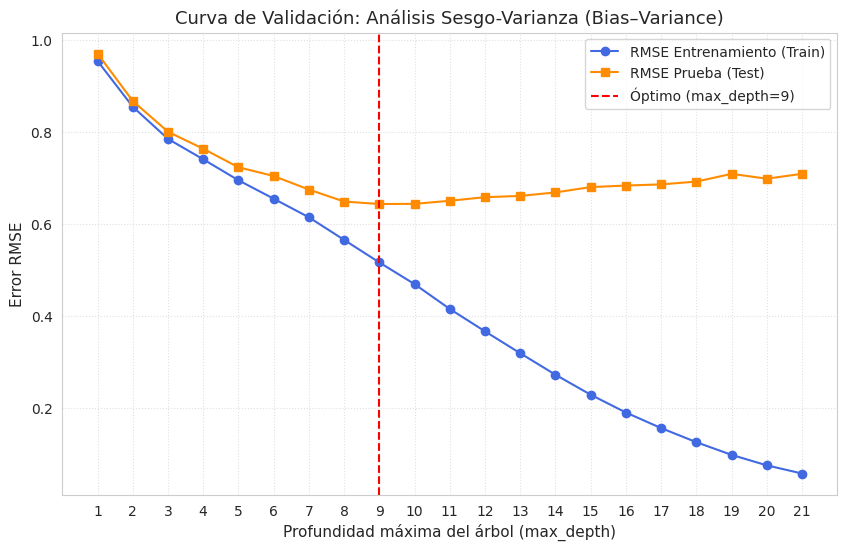

In [33]:
# 1.- Entrenar múltiples modelos variando el parámetro max_depth de 1 a 21
profundidades = list(range(1,22))
rmse_train = []
rmse_test = []

for depth in profundidades:
    modelo = DecisionTreeRegressor(max_depth=depth, random_state=42)
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)
    rmse_train.append(np.sqrt(mean_squared_error(y_train, pred_train)))
    rmse_test.append(np.sqrt(mean_squared_error(y_test, pred_test)))


# 2.- Identificar el punto donde el modelo generaliza mejor
mejor_idx = np.argmin(rmse_test)
mejor_profundidad = profundidades[mejor_idx]
menor_rmse_test = rmse_test[mejor_idx]

print(f"Mejor profundidad (max_depth): {mejor_profundidad}")
print(f"Menor RMSE en prueba: {menor_rmse_test:.4f}")
print(f"RMSE en entrenamiento para esa profundidad: {rmse_train[mejor_idx]:.4f}")

# 3.- Graficar el error (RMSE) en entrenamiento y prueba
plt.figure(figsize=(10, 6))
plt.plot(profundidades, rmse_train, label='RMSE Entrenamiento (Train)', marker='o', color='royalblue')
plt.plot(profundidades, rmse_test, label='RMSE Prueba (Test)', marker='s', color='darkorange')
plt.axvline(x=mejor_profundidad, color='red', linestyle='--', label=f'Óptimo (max_depth={mejor_profundidad})')
plt.title("Curva de Validación: Análisis Sesgo-Varianza (Bias–Variance)", fontsize=13)
plt.xlabel("Profundidad máxima del árbol (max_depth)", fontsize=11)
plt.ylabel("Error RMSE", fontsize=11)
plt.xticks(profundidades)
plt.legend()

plt.grid(True, linestyle=':', alpha=0.6)
plt.show()



### Conclusion - Bloque 4 Analisis Bias-Variance

* **Zona de alto sesgo (Underfitting, max_depth menor a 5):** Con niveles de profundidad reducidos, tanto el error de entrenamiento como el de prueba se mantienen elevados por encima de 0.8, lo que demuestra que el modelo carece de la complejidad necesaria para captar los patrones del conjunto de datos

* **Punto de equilibrio optimo (Mejor generalizacion):** Se alcanza el desempeno optimo en max_depth = 9, logrando el menor error sobre observaciones no vistas con un RMSE de prueba de 0.6443 y un RMSE de entrenamiento de 0.5172, punto exacto donde se equilibra el sesgo y la varianza antes de comenzar a memorizar ruido

* **Zona de alta varianza (Overfitting, max_depth mayor a 9):** A medida que la profundidad se incrementa, el error de entrenamiento continua reduciendose hasta valores cercanos a cero, mientras que el error de prueba se estanca y repunta por encima de 0.6, abriendo una brecha evidente que confirma la perdida de capacidad predictiva por exceso de ajuste

## Bloque 5. Poda del árbol


- 1.- Aplicar cost-complexity pruning (`ccp_alpha`)
- 2.- Evaluar distintos valores de `ccp_alpha` con `ccp_alphas = ccp_alphas[::5]`
- 3.- Analizar su efecto en el error del modelo

Total de valores alpha a evaluar: 80

Mejor ccp_alpha: 0.000303
Menor RMSE en prueba: 0.6392
RMSE en entrenamiento con ese alpha: 0.5432


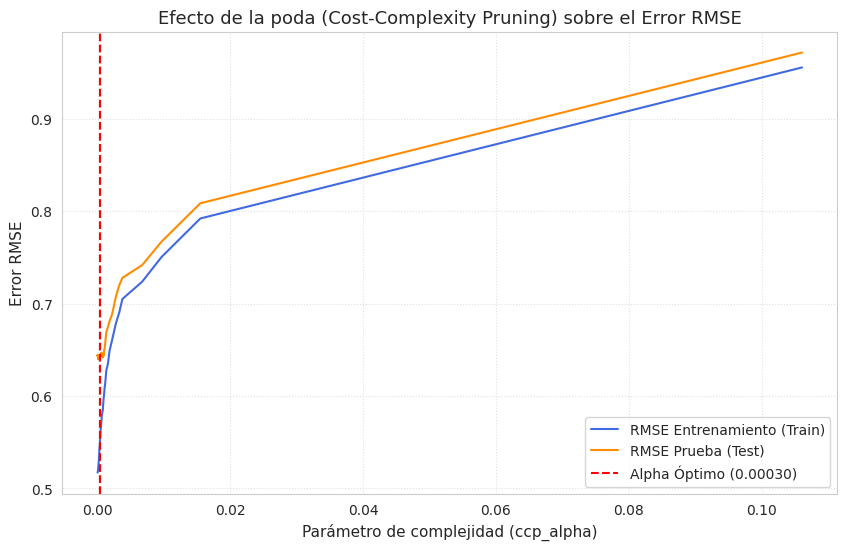

In [34]:
# 1.- Aplicar cost-complexity pruning (ccp_alpha)
arbol_poda = DecisionTreeRegressor(max_depth=9, random_state=42) #Se utiliza max_depth=9 por ser la profundidad optima identificada en el Bloque 4 y para optimizar el tiempo de ejecucion al evaluar ccp_alphas[::5]
path = arbol_poda.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1]

# 2.- Evaluar distintos valores de ccp_alpha con ccp_alphas = ccp_alphas[::5]
ccp_alphas = ccp_alphas[::5]
print(f"Total de valores alpha a evaluar: {len(ccp_alphas)}")
rmse_train = []
rmse_test = []
alphas_evaluados = []

for alpha in ccp_alphas:
    modelo_podado = DecisionTreeRegressor(random_state=42, max_depth=9, ccp_alpha=alpha)
    modelo_podado.fit(X_train, y_train)

    pred_train = modelo_podado.predict(X_train)
    pred_test = modelo_podado.predict(X_test)

    rmse_train.append(np.sqrt(mean_squared_error(y_train, pred_train)))
    rmse_test.append(np.sqrt(mean_squared_error(y_test, pred_test)))
    alphas_evaluados.append(alpha)

mejor_idx = np.argmin(rmse_test)
mejor_alpha = alphas_evaluados[mejor_idx]
menor_rmse_test = rmse_test[mejor_idx]

print(f"\nMejor ccp_alpha: {mejor_alpha:.6f}")
print(f"Menor RMSE en prueba: {menor_rmse_test:.4f}")
print(f"RMSE en entrenamiento con ese alpha: {rmse_train[mejor_idx]:.4f}")

# 3.- Analizar su efecto en el error del modelo
plt.figure(figsize=(10, 6))
plt.plot(alphas_evaluados, rmse_train, label='RMSE Entrenamiento (Train)', color='royalblue')
plt.plot(alphas_evaluados, rmse_test, label='RMSE Prueba (Test)', color='darkorange')
plt.axvline(x=mejor_alpha, color='red', linestyle='--', label=f'Alpha Óptimo ({mejor_alpha:.5f})')
plt.title("Efecto de la poda (Cost-Complexity Pruning) sobre el Error RMSE", fontsize=13)
plt.xlabel("Parámetro de complejidad (ccp_alpha)", fontsize=11)
plt.ylabel("Error RMSE", fontsize=11)
plt.legend()

plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Conclusion - Bloque 5 Poda del arbol

* **Identificacion del hiperparametro optimo:** De los 80 valores evaluados a lo largo de la ruta de poda con paso [::5] y profundidad 9, el punto optimo se localizo en ccp_alpha = 0.000303

* **Desempeno y generalizacion:** Con este valor de poda, el modelo alcanzo un RMSE en prueba de 0.6392 y un RMSE en entrenamiento de 0.5432, reduciendo la brecha entre curvas y manteniendo un equilibrio solido entre sesgo y varianza

* **Comparacion con el modelo base (Reduccion de sobreajuste):** El modelo base sin restricciones presentaba un RMSE en prueba de 0.7037 la poda por complejidad de costo logro reducir el error en mas de 0.06 unidades al suprimir ramas redundantes y ruidosas

* **Comportamiento ante valores mayores de alpha:** Cuando ccp_alpha supera el rango de 0.02, ambos errores (entrenamiento y prueba) aumentan por encima de 0.80, lo que evidencia que una poda excesiva conduce al underfitting y restringir al modelo su capacidad predictiva

## Bloque 6. Interpretación de resultados


Responder de manera justificada:

- 1.- ¿El modelo base presenta sobreajuste? Explique
- 2.- ¿Cómo afecta la profundidad del árbol al error?
- 3.- ¿Qué efecto tiene la poda en el modelo?
- 4.- ¿Cuál configuración produce el mejor desempeño?
- 5.- ¿Qué variables son más relevantes según el modelo?

Conclusion - Bloque 6 Interpretacion de resultados

* **1. Sobreajuste en el modelo base:** Si, presenta un sobreajuste severo. Al no limitar su crecimiento, el arbol memorizo las 16,512 observaciones de entrenamiento obteniendo un `RMSE` de 0.0 y un `R2` de 1.0, pero al evaluar datos no vistos de prueba su error se disparo a `RMSE` = 0.7037 con 34 niveles de profundidad y 15,854 nodos hoja

* **2. Efecto de la profundidad en el error:** A menor profundidad `max_depth menor a 5` predomina un underfitting con errores elevados tanto en entrenamiento como en prueba A partir de `max_depth = 9`, el error de prueba alcanza su minimo y luego comienza a subir mientras el de entrenamiento sigue cayendo, evidenciando un aumento de varianza overfitting

* **3. Efecto de la poda en el modelo:** La poda por complejidad de costo `ccp_alpha` recorta las ramas terminales que aportan poco poder explicativo o que memorizan ruido. Esto reduce la complejidad estructural del arbol y la varianza, mejorando la capacidad de generalizacion en el conjunto de prueba

* **4. Configuracion con mejor desempeno:** La mejor configuracion resulto de combinar `max_depth = 9` con `ccp_alpha = 0.000303` , alcanzando el menor error sobre datos no observados con un `RMSE` de prueba de 0.6392, superando al modelo base (0.7037) y al modelo unicamente limitado por profundidad (0.6443)


In [35]:
5 # Entrenar el modelo final óptimo
modelo_final = DecisionTreeRegressor(max_depth=9, ccp_alpha=0.000303, random_state=42)
modelo_final.fit(X_train, y_train)

# Importancia de las variables predictoras
importancias = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': modelo_final.feature_importances_}).sort_values(by='Importancia', ascending=False)

print(importancias.round(4))

     Variable  Importancia
0      MedInc       0.6457
5    AveOccup       0.1321
6    Latitude       0.0726
7   Longitude       0.0541
1    HouseAge       0.0427
2    AveRooms       0.0346
4  Population       0.0095
3   AveBedrms       0.0087


* **5. Variables mas relevantes:** La variable con mayor peso explicativo es el `MedInc`, superando ampliamente a las demas caracteristicas